# Difference between `nowcast.green` vs `flux`

## Surface Salinity

### Load data

In [2]:
import xarray as xr

path_flux='/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/SalishSea_1d_20230301_20230331_grid_T.nc'
path_green='/results2/SalishSea/nowcast-green.202111/01mar23/SalishSea_1d_20230301_20230301_grid_T.nc'


ds_flux=xr.open_dataset(path_flux)
ds_green=xr.open_dataset(path_green)

print(ds_green)

<xarray.Dataset> Size: 230MB
Dimensions:       (time_counter: 1, y: 898, x: 398, deptht: 40)
Coordinates:
  * time_counter  (time_counter) datetime64[ns] 8B 2023-03-01T12:00:00
  * y             (y) int64 7kB 0 1 2 3 4 5 6 7 ... 891 892 893 894 895 896 897
  * x             (x) int64 3kB 0 1 2 3 4 5 6 7 ... 391 392 393 394 395 396 397
  * deptht        (deptht) float32 160B 0.5 1.5 2.5 3.5 ... 387.6 414.5 441.5
Data variables:
    sossheig      (time_counter, y, x) float32 1MB ...
    votemper      (time_counter, deptht, y, x) float32 57MB ...
    vosaline      (time_counter, deptht, y, x) float32 57MB ...
    sigma_theta   (time_counter, deptht, y, x) float32 57MB ...
    e3t           (time_counter, deptht, y, x) float32 57MB ...
Attributes:
    name:         SalishSeaCast_1d_grid_T_20230301_20230301
    description:  Day-averaged physics tracers variables resampled from v2021...
    history:      2023-04-04 14:01 -07:00: Generated by reshapr.api.v1.extrac...
    Conventions:  CF-1.6

In [6]:
flux_sss=ds_flux['vosaline'].isel(time_counter=0, deptht=0)
green_sss=ds_green['vosaline'].isel(time_counter=0, deptht=0)
diff_sss=green_sss-flux_sss


### Visualize

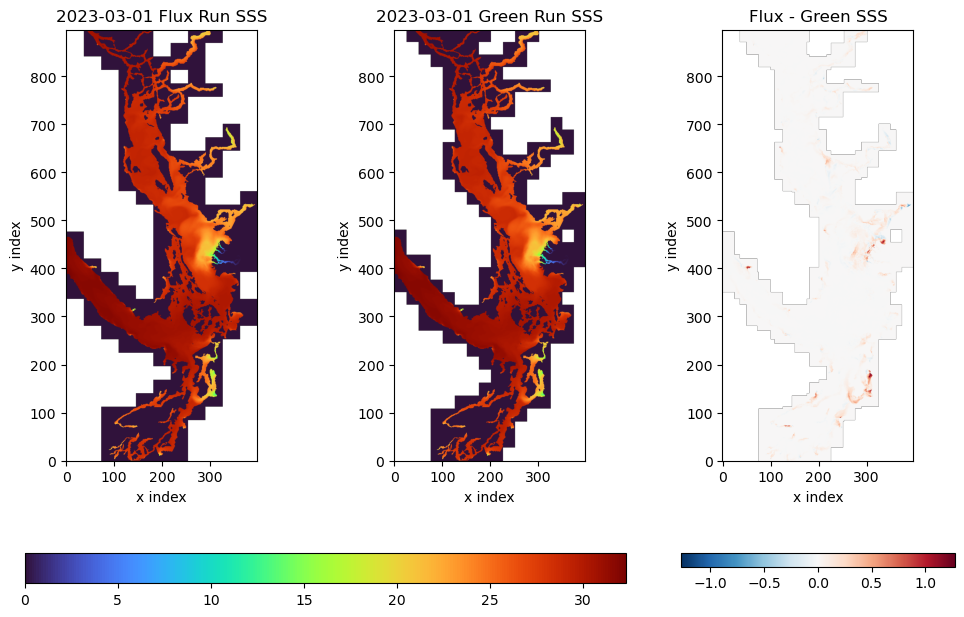

In [10]:
import matplotlib.pyplot as plt
import numpy as np

sss_vmin=np.nanmin(np.concatenate([flux_sss,green_sss]))
sss_vmax=np.nanmax(np.concatenate([flux_sss,green_sss]))
sss_vmax_diff=np.nanmax(diff_sss)

fig, axes = plt.subplots(1,3,figsize=(12, 8))

im_sss = axes[0].imshow(
    flux_sss,
    origin='lower',
    cmap='turbo',
    vmin=sss_vmin,
    vmax=sss_vmax,
    aspect='equal'
)

axes[0].set_title(
    '2023-03-01 Flux Run SSS'
)

axes[0].set_xlabel('x index')
axes[0].set_ylabel('y index')


axes[1].imshow(
    green_sss,
    origin='lower',
    cmap='turbo',
    vmin=sss_vmin,
    vmax=sss_vmax,
    aspect='equal'
)

axes[1].set_title(
    '2023-03-01 Green Run SSS'
)

axes[1].set_xlabel('x index')
axes[1].set_ylabel('y index')


im_diff = axes[2].imshow(
    diff_sss,
    origin='lower',
    cmap='RdBu_r',
    vmax=sss_vmax_diff,
    vmin=-sss_vmax_diff,
    aspect='equal'
)

axes[2].set_title(
    'Flux - Green SSS'
)

axes[2].set_xlabel('x index')
axes[2].set_ylabel('y index')

cbar_sss = fig.colorbar(
    im_sss,
    ax=axes[0:2],
    orientation='horizontal',
)

cbar_diff = fig.colorbar(
    im_diff,
    ax=axes[2],
    orientation='horizontal',
)

**No Obvious Systemic Difference?**

Maybe there is something wrong with `csv` extraction.

## Curves



### Puget Sound Area

Pearson correlation: r = 0.9999


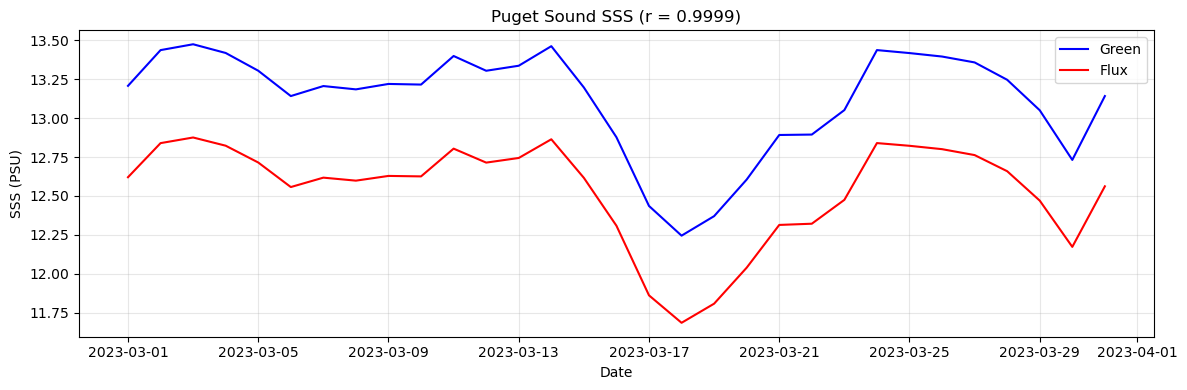

In [12]:
import pandas as pd 
import matplotlib.pyplot as plt

# paths

path_pgs_old='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/00MMM2023/Data_all_compare_old/physical/Puget_Sound_physical.csv'

path_pgs_new='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/00MMM2023/Data_all_compare/physical/Puget_Sound_physical.csv'

# Read data
df_old = pd.read_csv(path_pgs_old, parse_dates=['date'])
df_new = pd.read_csv(path_pgs_new, parse_dates=['date'])

# Match data by date
df = pd.merge(
    df_old[['date', 'HRDPS2.5__SSS']],
    df_new[['date', 'HRDPS2.5__SSS']],
    on='date',
    suffixes=('_old', '_new')
).sort_values('date').dropna()

# Pearson correlation
r = df['HRDPS2.5__SSS_old'].corr(df['HRDPS2.5__SSS_new'])
print(f'Pearson correlation: r = {r:.4f}')

# Plot
plt.figure(figsize=(12, 4))
plt.plot(df['date'], df['HRDPS2.5__SSS_old'],
         label='Green', color='blue', linewidth=1.5)
plt.plot(df['date'], df['HRDPS2.5__SSS_new'],
         label='Flux', color='red', linewidth=1.5)

plt.title(f'Puget Sound SSS (r = {r:.4f})')
plt.xlabel('Date')
plt.ylabel('SSS (PSU)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Puget Sound Random Point

Try (100, 260) for example. 

Pearson r = nan


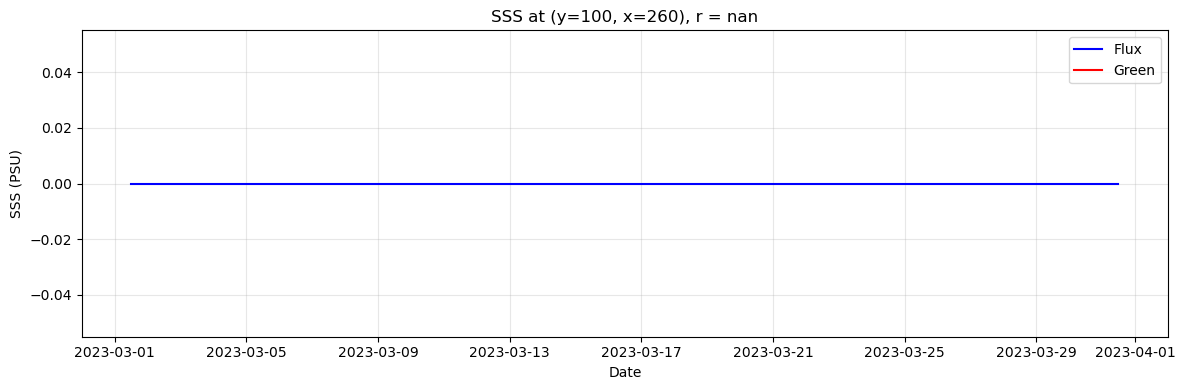

In [ ]:

import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

path_flux = '/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/SalishSea_1d_20230301_20230331_grid_T.nc'
path_green = '/results2/SalishSea/nowcast-green.202111/??mar23/SalishSea_1d_202303??_202303??_grid_T.nc'

# Read data
ds_flux = xr.open_dataset(path_flux)
ds_green = xr.open_mfdataset(path_green, combine='by_coords')

# Extract surface salinity at (y, x) = (100, 260)
sss_flux = ds_flux.vosaline.isel(deptht=0, y=100, x=260)
sss_green = ds_green.vosaline.isel(deptht=0, y=100, x=260)

# Convert to pandas Series
flux = sss_flux.to_series()
green = sss_green.to_series()

# Match dates and calculate correlation
df = pd.concat([flux.rename('Flux'), green.rename('Green')], axis=1).dropna()
r = df['Flux'].corr(df['Green'])
print(f'Pearson r = {r:.4f}')

# Plot
plt.figure(figsize=(12, 4))
plt.plot(flux.index, flux, label='Flux', color='blue')
plt.plot(green.index, green, label='Green', color='red')

plt.title(f'SSS at (y=100, x=260), r = {r:.4f}')
plt.xlabel('Date')
plt.ylabel('SSS (PSU)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
